# Waterfall H5 — Global / Rolling median background

Đọc hai H5 và hiển thị waterfall của cả hai. **File 2 là dữ liệu cần xử lý**. Mặc định, nền lấy từ chính File 2 theo thuật toán trong ảnh; File 1 vẫn được hiển thị để đối chiếu.

Chọn `BACKGROUND_METHOD` ở cell cấu hình:
- `"target_global"`: median theo toàn bộ thời gian của File 2, riêng từng bin tần số.
- `"target_rolling"`: median trên cửa sổ **60 giây** trong File 2; tính bằng timestamps thực, không dùng số bin hoặc số bản ghi cố định.
- `"night_median"`: giữ cách cũ, lấy median File 1 làm nền cho File 2.

Công thức: \(P=10\log_{10}(|S12|+\epsilon)\), \(R=P-B\); khi vẽ clipped dùng \(\max(0,R)\). Mảng `residual_db` luôn giữ dấu. Không tái tạo S12 phức hoặc tính phase/fringe từ phần dư.

**Giới hạn:** median làm mốc nền, không phân biệt RFI với tín hiệu trời. Vạch thay đổi/trôi vẫn có phần dư. Global median có thể đưa sự kiện chiếm phần lớn thời gian vào nền; rolling median có thể làm suy giảm sự kiện kéo dài trong cửa sổ. Không có ngưỡng 15 phút bảo đảm Global tốt hơn. Rolling trong notebook là xử lý offline, dùng cả dữ liệu trước và sau thời điểm đang xét.

## Chạy trong VS Code
1. Cài extensions Python, Jupyter; chọn Python kernel.
2. Cài thư viện: `python -m pip install numpy h5py matplotlib ipykernel` (hoặc `%pip install ...` trong notebook).
3. Sửa `DATA_DIR` và tên `FILE_1`, `FILE_2`; Windows dùng ví dụ `Path(r"C:\Users\Tuch\Documents\VGU\Thesis\Storage\2026-10-24")`.
4. Bấm **Run All**. Các output đính kèm được tạo với `target_global` trên file 10:15 ngày 24/10/2026; thay file thì chạy lại toàn bộ.

Notebook chỉ đọc H5; không thay nội dung đầu vào. Output chỉ là mức tương đối sau trừ nền, không chứng nhận sạch RFI.


## Chỉnh thang màu như ảnh viewer

Sửa `RAW_VMIN_DB = 18`, `RAW_VMAX_DB = 40` và `WATERFALL_CMAP = "inferno"` ở cell cấu hình, rồi chạy lại các cell vẽ. Hai ảnh gốc dùng chung thang cố định. Phần dư mặc định −12..12 dB (signed) hoặc 0..12 dB (clipped), có biến riêng để thay đổi. Không dùng 18..40 dB của phổ gốc làm mặc định cho phần dư tương đối.

Giới hạn màu chỉ đổi cách tô màu: giá trị vượt giới hạn bão hòa ở hai đầu, không sửa dữ liệu hay phép trừ nền. Bản clipped vẫn giữ mảng `residual_db` có dấu riêng.


In [40]:
from pathlib import Path
from datetime import datetime, timezone, timedelta
import warnings
import numpy as np
import h5py
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import TwoSlopeNorm

# SỬA TẠI ĐÂY. DATA_DIR là thư mục chứa hai H5 trên máy bạn.
DATA_DIR = Path(r"C:\Users\Tuch\Documents\VGU\Thesis\Storage\2026-10-24")
FILE_1 = DATA_DIR / "2026-10-24_02-15-09_UTC+0700_13731914092555676744_51.h5"  # nền đêm
FILE_2 = DATA_DIR / "2026-10-24_13-31-01_UTC+0700_13731914092555676744_96.h5"  # ban ngày

BACKGROUND_METHOD = "target_rolling"  # "target_global", "target_rolling", "night_median"
ROLLING_WINDOW_SECONDS = 180.0
ROLLING_MIN_VALID_SAMPLES = 3  # mỗi bin cần ít nhất số mẫu hợp lệ này trong cửa sổ
EPSILON_LINEAR = 1e-12  # đơn vị giống |S12|; ảnh thuật toán không chỉ định epsilon
DISPLAY_TIMEZONE = timezone(timedelta(hours=7))
# None: hiện toàn dải. Ví dụ (38.7, 39.2) để zoom tần số; không đổi miền tính nền.
DISPLAY_FREQ_MHZ = None
# THANG MÀU: giống trục colorbar trong ảnh viewer, chỉnh tại đây.
WATERFALL_CMAP = "inferno"
RAW_VMIN_DB, RAW_VMAX_DB = 18., 40.        # hai waterfall gốc
SIGNED_VMIN_DB, SIGNED_VMAX_DB = -12., 12. # phần dư giữ dấu
RESIDUAL_VMIN_DB, RESIDUAL_VMAX_DB = 0., 12. # phần dư cắt âm để vẽ
for lower, upper in ((RAW_VMIN_DB, RAW_VMAX_DB), (SIGNED_VMIN_DB, SIGNED_VMAX_DB),
                     (RESIDUAL_VMIN_DB, RESIDUAL_VMAX_DB)):
    if not np.isfinite(lower + upper) or upper <= lower:
        raise ValueError("Giới hạn màu phải hữu hạn và min < max.")
SAVE_PNG = False
PNG_PATH = DATA_DIR / "waterfall_adaptive_background.png"

for path in (FILE_1, FILE_2):
    if not path.is_file():
        raise FileNotFoundError(f"Không tìm thấy {path.resolve()}. Sửa DATA_DIR hoặc đường dẫn FILE_1/FILE_2.")
assert np.isfinite(EPSILON_LINEAR) and EPSILON_LINEAR > 0
print("File 1 (nền):", FILE_1.resolve())
print("File 2 (đích):", FILE_2.resolve())


File 1 (nền): C:\Users\Tuch\Documents\VGU\Thesis\Storage\2026-10-24\2026-10-24_02-15-09_UTC+0700_13731914092555676744_51.h5
File 2 (đích): C:\Users\Tuch\Documents\VGU\Thesis\Storage\2026-10-24\2026-10-24_13-31-01_UTC+0700_13731914092555676744_96.h5


## Đọc schema H5 gốc

Đọc `/data/s12_real`, `/data/s12_imag`, S11/S22 và thời gian UTC đã lưu. Loại mẫu thiếu/không hữu hạn, S11/S22 không dương hoặc coherence vượt 1 quá sai số cho phép 1e−5. Không dùng coherence cao làm bằng chứng RFI; không dùng ngưỡng hiển thị phase để lọc nền.

Dữ liệu đọc theo block; kết quả biên độ được giữ trong RAM cho notebook. Số ô tối đa có chặn để tránh vô tình đọc một file quá lớn. Không gộp tần số, không nội suy. Các khoảng đứt thời gian được vẽ thành segment riêng. Thời gian H5 của cặp file này là UTC ước lượng, không phải mốc thời gian phần cứng đã xác nhận.


In [41]:
EXPECTED_UNITS = "ADC-count^2 per input FFT bin (mean after frequency grouping)"

def decode_text(value):
    return value.decode("utf-8") if isinstance(value, bytes) else str(value)

def read_observation(path, max_cells=20_000_000, block_rows=256):
    with h5py.File(path, "r") as h:
        meta = dict(h["metadata"].attrs)
        if int(meta.get("data_schema_version", -1)) != 1:
            raise ValueError(f"{path.name}: cần H5 schema 1.")
        if decode_text(meta.get("units", "")) != EXPECTED_UNITS:
            raise ValueError(f"{path.name}: đơn vị chưa được hỗ trợ.")
        frequency = np.asarray(h["frequency_hz"][:], dtype=np.float64)
        if (frequency.ndim != 1 or len(frequency) < 2
                or not np.isfinite(frequency).all() or not (np.diff(frequency) > 0).all()):
            raise ValueError("Trục tần số phải hữu hạn, tăng dần, ít nhất 2 bin.")
        bandwidth = float(meta["frequency_bin_bandwidth_hz"])
        if not np.isfinite(bandwidth) or bandwidth <= 0 or not np.allclose(np.diff(frequency), bandwidth, rtol=1e-8, atol=1e-4):
            raise ValueError("Notebook này cần trục tần số đều như schema viewer.")
        d = h["data"]
        shape = d["s12_real"].shape
        if len(shape) != 2 or shape[1] != len(frequency) or shape[0] == 0:
            raise ValueError("Dạng phổ H5 không hợp lệ.")
        if np.prod(shape) > max_cells:
            raise ValueError("File quá lớn cho giới hạn RAM của notebook. Chọn file nhỏ hơn hoặc chủ động tăng max_cells.")
        names = ("s11_linear", "s22_linear", "s12_real", "s12_imag")
        if any(d[name].shape != shape or d[name].dtype.kind != "f" for name in names):
            raise ValueError("Các thống kê S11/S22/Re/Im phải cùng shape và có kiểu float.")
        starts = np.asarray(d["start_utc_us"][:], dtype=np.float64) / 1e6
        ends = np.asarray(d["end_utc_us"][:], dtype=np.float64) / 1e6
        weights = np.asarray(d["valid_fft_frames"][:], dtype=np.float64)
        flags = d["quality_flags"][:]
        if (starts.shape != (shape[0],) or ends.shape != starts.shape or weights.shape != starts.shape
                or flags.shape != starts.shape or not np.isfinite(starts).all() or not np.isfinite(ends).all()
                or not (ends > starts).all() or not (np.diff(starts) > 0).all()
                or not np.isfinite(weights).all() or not (weights > 0).all()):
            raise ValueError("Thời gian/trọng số không hợp lệ.")
        magnitude = np.full(shape, np.nan, dtype=np.float64)
        for first in range(0, shape[0], block_rows):
            last = min(first + block_rows, shape[0])
            a, b, re, im = [d[name][first:last].astype(np.float64) for name in names]
            amp = np.hypot(re, im)
            with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
                gamma = amp / np.sqrt(a * b)
            valid = (np.isfinite(a) & np.isfinite(b) & np.isfinite(re) & np.isfinite(im)
                     & (a > 0) & (b > 0) & (gamma <= 1 + 1e-5))
            magnitude[first:last] = np.where(valid, amp, np.nan)
        breaks = np.zeros(shape[0], dtype=bool)
        breaks[0] = True
        breaks[1:] = np.abs(starts[1:] - ends[:-1]) > .002  # split UTC gaps/overlaps >2 ms
        if "sample_start" in d and "sample_end" in d and "hop_samples" in meta:
            ss, se = d["sample_start"][:], d["sample_end"][:]
            if ss.shape != starts.shape or se.shape != starts.shape:
                raise ValueError("Dạng sample support không hợp lệ.")
            # Python integers tránh tràn/underflow khi trừ uint64.
            breaks[1:] |= np.array([int(ss[i]) != int(se[i-1])-int(meta["hop_samples"])
                                   for i in range(1, shape[0])])
        breaks |= (flags.astype(np.uint64) & (8 | 16)) != 0
        return dict(path=path, meta=meta, frequency_hz=frequency, bandwidth_hz=bandwidth,
                    magnitude=magnitude, starts=starts, ends=ends, breaks=breaks,
                    valid_fft_frames=weights, quality_flags=flags)

night = read_observation(FILE_1)
day = read_observation(FILE_2)
if not np.array_equal(night["frequency_hz"], day["frequency_hz"]):
    raise ValueError("Hai file khác trục tần số. Dừng phép trừ; không tự nội suy.")
for key in ("config_hash", "calibration_id", "phase_calibrated", "cross_product_convention"):
    if decode_text(night["meta"].get(key, "")) != decode_text(day["meta"].get(key, "")):
        warnings.warn(f"Hai file khác {key}; cần kiểm tra khả năng so sánh nền.")
for label, obs in (("File 1 / đêm", night), ("File 2 / ngày", day)):
    begin = datetime.fromtimestamp(obs["starts"][0], DISPLAY_TIMEZONE)
    end = datetime.fromtimestamp(obs["ends"][-1], DISPLAY_TIMEZONE)
    print(f"{label}: {obs['magnitude'].shape}; {begin:%Y-%m-%d %H:%M:%S} → {end:%H:%M:%S} UTC+07")
    print(f"  Δf = {obs['bandwidth_hz']:.7f} Hz; ô hợp lệ = {np.isfinite(obs['magnitude']).mean():.3%}")
    print("  Số FFT tích phân/bản ghi:", np.unique(obs["valid_fft_frames"]))


File 1 / đêm: (751, 2048); 2026-10-24 02:15:09 → 02:30:10 UTC+07
  Δf = 4882.8125000 Hz; ô hợp lệ = 100.000%
  Số FFT tích phân/bản ghi: [11718.]
File 2 / ngày: (751, 2048); 2026-10-24 13:31:01 → 13:46:02 UTC+07
  Δf = 4882.8125000 Hz; ô hợp lệ = 100.000%
  Số FFT tích phân/bản ghi: [11718.]


## Tính nền theo chế độ đã chọn

Mỗi bin tần số có một nền riêng. Global lấy median cả thời gian File 2; Rolling dùng timestamps trong cửa sổ giây và tách ở gap/session boundary. Không có mẫu hợp lệ thì giữ NaN. Epsilon chọn rõ ràng là 1e−12 vì ảnh không quy định giá trị. Không tự đổi gain, không nội suy, không dùng lưới harmonic 500 kHz.


In [42]:
def rolling_median_seconds(values, starts, ends, breaks, window_seconds, min_samples=3):
    """Offline centered window, clipped at segment edges; never crosses a gap.

    Full window 60 s uses up to 30 s future data. Near segment edges,
    a shorter window is used; fewer than min_samples finite samples => NaN.
    """
    if not np.isfinite(window_seconds) or window_seconds <= 0:
        raise ValueError("ROLLING_WINDOW_SECONDS phải dương và hữu hạn.")
    if not isinstance(min_samples, (int, np.integer)) or min_samples < 1:
        raise ValueError("ROLLING_MIN_VALID_SAMPLES phải là số nguyên dương.")
    values = np.asarray(values, dtype=float)
    centers = (np.asarray(starts) + np.asarray(ends)) / 2
    if len(values) != len(centers) or len(breaks) != len(centers):
        raise ValueError("Sai số hàng thời gian.")
    result = np.full_like(values, np.nan)
    firsts = np.flatnonzero(breaks)
    if not len(firsts) or firsts[0] != 0:
        raise ValueError("Segment đầu phải bắt đầu ở hàng 0.")
    for first, stop in zip(firsts, np.r_[firsts[1:], len(values)]):
        times = centers[first:stop]
        for offset, instant in enumerate(times):
            lo = first + np.searchsorted(times, instant-window_seconds/2, side="left")
            hi = first + np.searchsorted(times, instant+window_seconds/2, side="right")
            part = values[lo:hi]
            count = np.isfinite(part).sum(axis=0)
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)
                med = np.nanmedian(part, axis=0)
            result[first+offset] = np.where(count >= min_samples, med, np.nan)
    return result

night_db = 10 * np.log10(night["magnitude"] + EPSILON_LINEAR)
day_db = 10 * np.log10(day["magnitude"] + EPSILON_LINEAR)
if BACKGROUND_METHOD == "night_median":
    reference_db = night_db
    background_label = "File 1 / night median"
elif BACKGROUND_METHOD == "target_global":
    reference_db = day_db
    background_label = "File 2 / global time median"
elif BACKGROUND_METHOD == "target_rolling":
    reference_db = day_db
    background_label = f"File 2 / centered rolling median ({ROLLING_WINDOW_SECONDS:g} s)"
else:
    raise ValueError("BACKGROUND_METHOD không hợp lệ.")

if BACKGROUND_METHOD == "target_rolling":
    background_db = rolling_median_seconds(day_db, day["starts"], day["ends"], day["breaks"],
                                           ROLLING_WINDOW_SECONDS, ROLLING_MIN_VALID_SAMPLES)
else:
    count = np.sum(np.isfinite(reference_db), axis=0)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        background_db = np.nanmedian(reference_db, axis=0)
    background_db[count == 0] = np.nan
residual_db = day_db - background_db  # broadcasting 1D global or 2D rolling background
residual_display_db = np.maximum(residual_db, 0)  # separate display array only
print("Nền:", background_label)
print("Cadence trung vị File 2:", float(np.median(np.diff((day["starts"]+day["ends"])/2))), "s/record")
print("Số ô phần dư âm được giữ:", int((residual_db < 0).sum()))
print("Tỷ lệ ô phần dư hữu hạn:", f"{np.isfinite(residual_db).mean():.3%}")
if BACKGROUND_METHOD == "target_rolling":
    print(f"Offline: cửa sổ đối xứng dùng tối đa {ROLLING_WINDOW_SECONDS/2:g} s dữ liệu tương lai; không vượt gap.")


Nền: File 2 / centered rolling median (180 s)
Cadence trung vị File 2: 1.199923038482666 s/record
Số ô phần dư âm được giữ: 771278
Tỷ lệ ô phần dư hữu hạn: 100.000%
Offline: cửa sổ đối xứng dùng tối đa 90 s dữ liệu tương lai; không vượt gap.


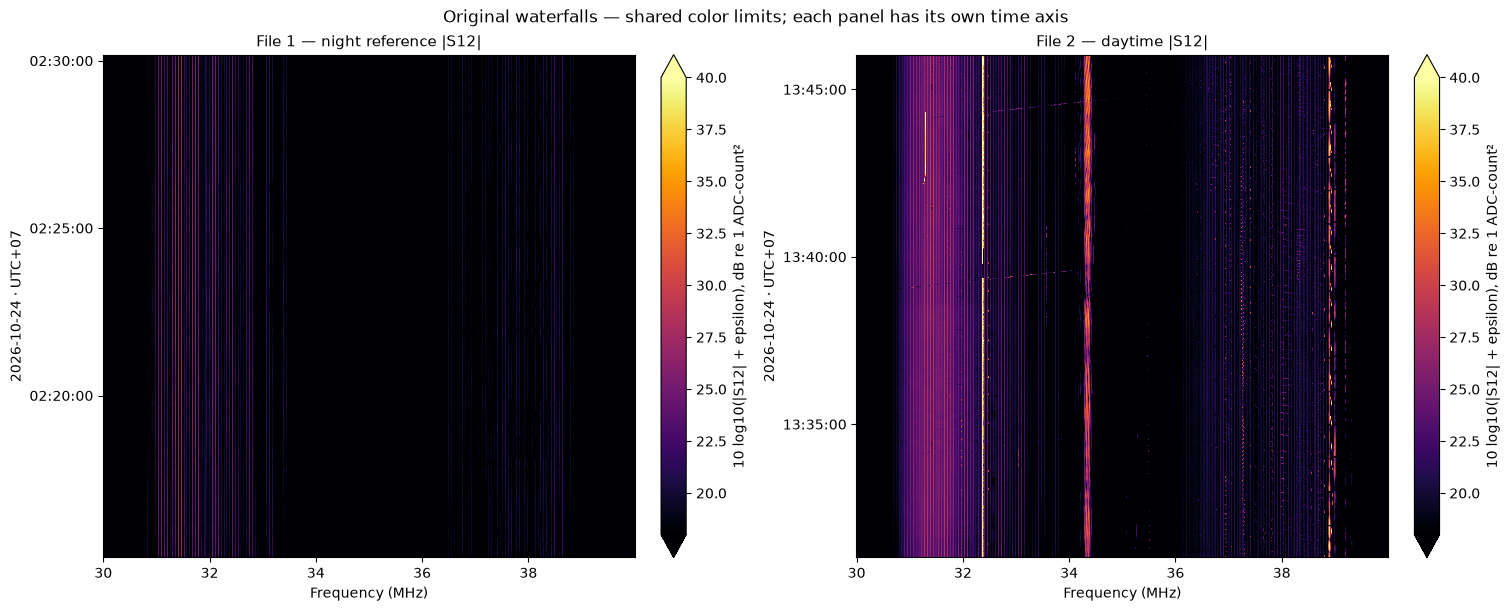

In [43]:
def finite_percentile(values, q):
    finite = np.asarray(values)[np.isfinite(values)]
    if not finite.size:
        raise ValueError("Không còn dữ liệu hữu hạn để vẽ.")
    return np.percentile(finite, q)

def plot_waterfall(ax, obs, values, title, cmap, norm=None, vmin=None, vmax=None):
    f = obs["frequency_hz"]
    half = obs["bandwidth_hz"] / 2
    freq_edges = np.r_[f - half, f[-1] + half] / 1e6
    segment_starts = np.flatnonzero(obs["breaks"])
    segment_ends = np.r_[segment_starts[1:], len(values)]
    epoch = mdates.date2num(datetime(1970, 1, 1, tzinfo=timezone.utc))
    mesh = None
    for first, stop in zip(segment_starts, segment_ends):
        # UTC row-start boundaries plus last support end; no interpolation across gaps.
        time_edges = np.r_[obs["starts"][first:stop], obs["ends"][stop-1]] / 86400 + epoch
        kwargs = {"norm": norm} if norm is not None else {"vmin": vmin, "vmax": vmax}
        mesh = ax.pcolormesh(freq_edges, time_edges, values[first:stop], shading="flat",
                             cmap=cmap, rasterized=True, **kwargs)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel(datetime.fromtimestamp(obs["starts"][0], DISPLAY_TIMEZONE).strftime("%Y-%m-%d") + " · UTC+07")
    ax.yaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=7))
    ax.yaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S", tz=DISPLAY_TIMEZONE))
    ax.set_xlim(*(DISPLAY_FREQ_MHZ if DISPLAY_FREQ_MHZ is not None else (freq_edges[0], freq_edges[-1])))
    return mesh

# Hai ảnh gốc dùng chung thang màu để so sánh mức tín hiệu.
lo, hi = RAW_VMIN_DB, RAW_VMAX_DB
fig_raw, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
for ax, obs, values, title in zip(axes, (night, day), (night_db, day_db),
                                  ("File 1 — night reference |S12|", "File 2 — daytime |S12|")):
    mesh = plot_waterfall(ax, obs, values, title, WATERFALL_CMAP, vmin=lo, vmax=hi)
    fig_raw.colorbar(mesh, ax=ax, label="10 log10(|S12| + epsilon), dB re 1 ADC-count²", extend="both")
fig_raw.suptitle("Original waterfalls — shared color limits; each panel has its own time axis")
plt.show()


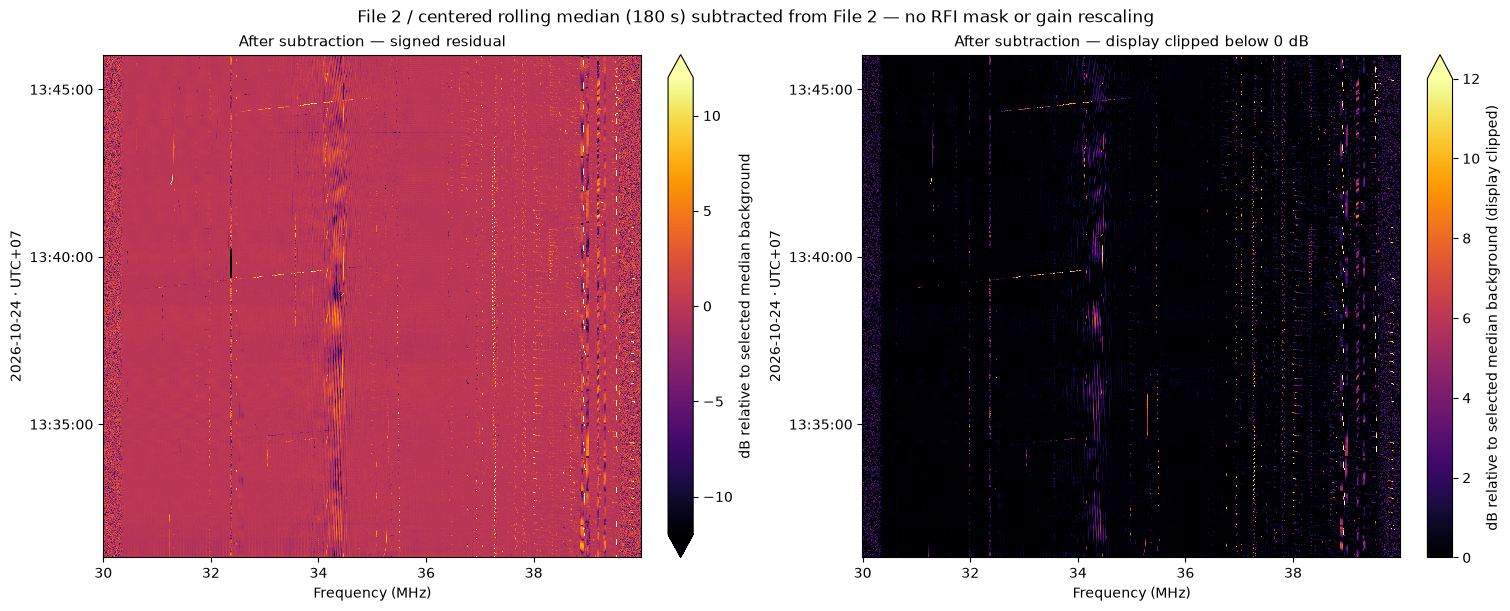

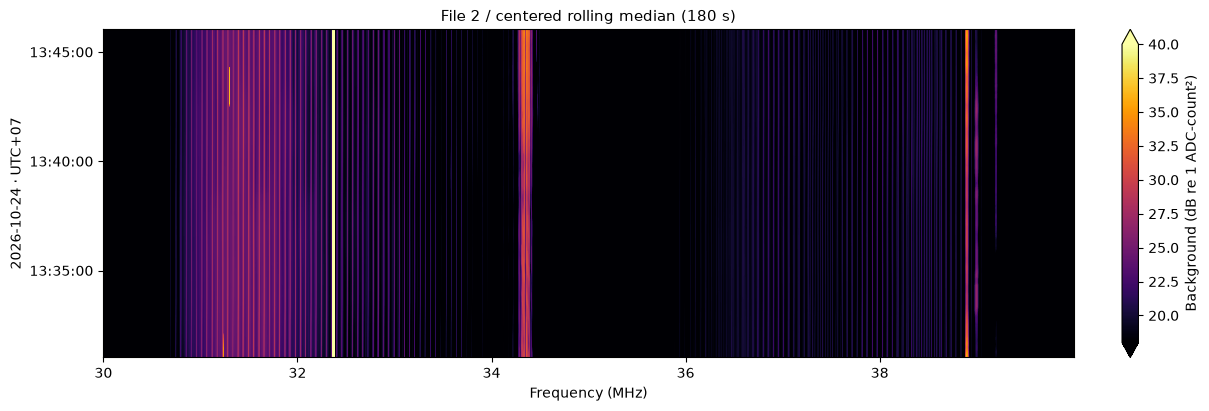

In [44]:
# Tính giới hạn từ dữ liệu chỉ để tô màu; không cắt hay thay đổi residual_db.
fig_result, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
mesh = plot_waterfall(axes[0], day, residual_db, "After subtraction — signed residual", WATERFALL_CMAP,
                      vmin=SIGNED_VMIN_DB, vmax=SIGNED_VMAX_DB)
fig_result.colorbar(mesh, ax=axes[0], label="dB relative to selected median background", extend="both")
mesh = plot_waterfall(axes[1], day, residual_display_db, "After subtraction — display clipped below 0 dB", WATERFALL_CMAP,
                      vmin=RESIDUAL_VMIN_DB, vmax=RESIDUAL_VMAX_DB)
fig_result.colorbar(mesh, ax=axes[1], label="dB relative to selected median background (display clipped)", extend="max")
fig_result.suptitle(background_label + " subtracted from File 2 — no RFI mask or gain rescaling")
plt.show()

# Kiểm tra nền đã dùng; Rolling được vẽ thành waterfall, Global thành vector.
fig_background, ax = plt.subplots(figsize=(12, 4), layout="constrained")
if background_db.ndim == 1:
    ax.plot(day["frequency_hz"] / 1e6, background_db, linewidth=.8)
    ax.set(xlabel="Frequency (MHz)", ylabel="Median background (dB)", title=background_label)
    ax.grid(alpha=.25)
else:
    mesh = plot_waterfall(ax, day, background_db, background_label, WATERFALL_CMAP,
                          vmin=RAW_VMIN_DB, vmax=RAW_VMAX_DB)
    fig_background.colorbar(mesh, ax=ax, label="Background (dB re 1 ADC-count²)", extend="both")
plt.show()

if SAVE_PNG:
    fig_raw.savefig(PNG_PATH.with_name(PNG_PATH.stem + "_originals.png"), dpi=180)
    fig_result.savefig(PNG_PATH, dpi=180)
    print("Đã lưu PNG:", PNG_PATH.resolve())


## Kiểm tra

Kiểm tra công thức và việc giữ dấu, cùng Rolling trên dữ liệu tổng hợp có gap/NaN. Kết quả dùng tiếp: `background_db`, `residual_db`, `residual_display_db`. Median phần dư bằng 0 không đồng nghĩa từng ô bằng 0 hay mọi vạch là RFI. H5 đầu vào không thay đổi.


In [45]:
np.testing.assert_allclose(residual_db, day_db-background_db, rtol=0, atol=0, equal_nan=True)
np.testing.assert_allclose(residual_display_db, np.maximum(residual_db,0), rtol=0, atol=0, equal_nan=True)
if BACKGROUND_METHOD == "target_global":
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        median_residual = np.nanmedian(residual_db, axis=0)
    np.testing.assert_allclose(median_residual[np.isfinite(median_residual)], 0, atol=1e-12, rtol=0)

# Kiểm tra Rolling trên dữ liệu biết trước, gồm gap và thiếu mẫu.
x = np.array([[0.,np.nan],[2.,np.nan],[10.,4.],[100.,8.],[102.,10.]])
b = np.array([True,False,False,True,False])
r = rolling_median_seconds(x, np.arange(5.), np.arange(5.)+.5, b, 100., 1)
np.testing.assert_allclose(r[:,0], [2.,2.,2.,101.,101.])
assert np.isnan(rolling_median_seconds(x, np.arange(5.), np.arange(5.)+.5, b, 100., 3)[3:]).all()
np.testing.assert_allclose(r[:3,1],4.)
print("Kiểm tra công thức, Global median, Rolling/gap/NaN: PASS")


Kiểm tra công thức, Global median, Rolling/gap/NaN: PASS
